<a href="https://colab.research.google.com/github/qtrong0205/plant-care-ai-service/blob/main/classification/training/train_plant_disease_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Plant Care - Classification

In [1]:
!git clone https://github.com/qtrong0205/plant-care-ai-service
%cd plant-care-ai-service/classification/training

Cloning into 'plant-care-ai-service'...
remote: Enumerating objects: 35, done.
remote: Counting objects: 100% (35/35), done.
remote: Compressing objects: 100% (21/21), done.
remote: Total 35 (delta 7), reused 30 (delta 6), pack-reused 0 (from 0)
Receiving objects: 100% (35/35), 206.08 KiB | 2.68 MiB/s, done.
Resolving deltas: 100% (7/7), done.
/content/plant-care-ai-service/classification/training


## 1. Problem Definition

- 1.1. Objective

  The objective of this project is to build a deep learning model that automatically classifies plant diseases from leaf images. The trained model will be deployed as an **ONNX model** in a FastAPI service to provide real-time disease diagnosis for the Plant Care Assistant application.

- 1.2. Dataset

  The model is trained on the **PlantVillage** dataset, which contains approximately 54,000 images across 38 classes covering 14 plant species and their disease categories. To accelerate experimentation and hyperparameter tuning, the initial training will use only 20% of the training dataset (approximately 10,000 images). After selecting the best configuration, the final model will be trained on the full dataset.

- 1.3. Evaluation Metrics

  Model performance will be evaluated using Accuracy, Precision, Recall, F1-score, and the Confusion Matrix.

## 2. Import libraries and Setup device agnostic code

In [2]:
import os
import torch
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pathlib import Path

In [3]:
# Device agnostic code
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cpu'

## 3. Load & Explore Data



### 3.1. Download and unzip data

In [4]:
from pathlib import Path

DATA_DIR = Path("data/plantvillage dataset/color")

if DATA_DIR.exists() and any(DATA_DIR.iterdir()):
    print(f"Dataset already exist at '{DATA_DIR}', download skipped.")
else:
    print("Downloading data from Kaggle...")
    !kaggle datasets download -d abdallahalidev/plantvillage-dataset
    !unzip -q plantvillage-dataset.zip -d data/
    print("Downloaded and unziped.")

Dataset URL: https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset
License(s): CC-BY-NC-SA-4.0
100% 2.04G/2.04G [00:12<00:00, 182MB/s]

Downloaded and unziped.


In [5]:
from split_dataset import split_dataset

SPLIT_PATH = Path("data/split")
train_path = Path("data/split/train")
test_path = Path("data/split/test")

if train_path.exists() and test_path.exists() and len(list(train_path.iterdir())) == 38:
    print("Already splitted")
else:
    split_dataset(
        source_dir="data/plantvillage dataset/color",
        output_dir=SPLIT_PATH,
        train_ratio=0.8,
    )

Dataset successfully split into 'data/split'.


### 3.2. Create a Custom `ImageDataset` Class

In this section, we implement a custom `ImageDataset` class that accepts the dataset directory, image transformations, and a subset ratio. The `subset_ratio` parameter allows loading only a specified percentage of the original dataset, enabling faster experimentation and model training.

The implementation of the `ImageDataset` class is available in the project repository:

> **GitHub:** https://github.com/qtrong0205/plant-care-ai-service/blob/main/classification/training/data_setup.py

In [6]:
from data_setup import ImageDataset

# Create a dataset with custom ImageDataset
train_dataset = ImageDataset(
    targ_dir=train_path,
    transform=None,
    subset_ratio=0.2,
    seed=42,
)
test_dataset = ImageDataset(
    targ_dir=test_path,
    transform=None,
    subset_ratio=0.2,
    seed=42,
)

print(f"Number of classes in train dataset: {len(train_dataset.classes)}")
print(f"Number of images in train dataset: {len(train_dataset)}")
print(f"Number of classes in test dataset: {len(test_dataset.classes)}")
print(f"Number of images in test dataset: {len(test_dataset)}")

Number of classes in train dataset: 38
Number of images in train dataset: 8673
Number of classes in test dataset: 38
Number of images in test dataset: 2165


In [7]:
from data_setup import find_classes

class_names, class_to_idx = find_classes(train_path)
class_names

['Apple___Apple_scab',
 'Apple___Black_rot',
 'Apple___Cedar_apple_rust',
 'Apple___healthy',
 'Blueberry___healthy',
 'Cherry_(including_sour)___Powdery_mildew',
 'Cherry_(including_sour)___healthy',
 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot',
 'Corn_(maize)___Common_rust_',
 'Corn_(maize)___Northern_Leaf_Blight',
 'Corn_(maize)___healthy',
 'Grape___Black_rot',
 'Grape___Esca_(Black_Measles)',
 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',
 'Grape___healthy',
 'Orange___Haunglongbing_(Citrus_greening)',
 'Peach___Bacterial_spot',
 'Peach___healthy',
 'Pepper,_bell___Bacterial_spot',
 'Pepper,_bell___healthy',
 'Potato___Early_blight',
 'Potato___Late_blight',
 'Potato___healthy',
 'Raspberry___healthy',
 'Soybean___healthy',
 'Squash___Powdery_mildew',
 'Strawberry___Leaf_scorch',
 'Strawberry___healthy',
 'Tomato___Bacterial_spot',
 'Tomato___Early_blight',
 'Tomato___Late_blight',
 'Tomato___Leaf_Mold',
 'Tomato___Septoria_leaf_spot',
 'Tomato___Spider_mites Two-spotted_

### 3.3. Visualize an image

Random image path: data/split/test/Corn_(maize)___healthy/6bb4c303-7e34-43a6-8eca-20a171672c31___R.S_HL 8089 copy 2.jpg
Image class: Corn_(maize)___healthy
Image height: 256
Image width: 256


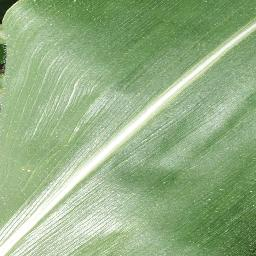

In [8]:
import random
from PIL import Image

# Set seed
# random.seed(42)

# 1. Get all image paths (* means "any combination")
image_path_list = list(SPLIT_PATH.glob("*/*/*.jpg"))

# 2. Get random image path
random_image_path = random.choice(image_path_list)

# 3. Get image class from path name (the image class is the name of the directory where the image is stored)
image_class = random_image_path.parent.stem

# 4. Open image
img = Image.open(random_image_path)

# 5. Print metadata
print(f"Random image path: {random_image_path}")
print(f"Image class: {image_class}")
print(f"Image height: {img.height}")
print(f"Image width: {img.width}")
img

(np.float64(-0.5), np.float64(255.5), np.float64(255.5), np.float64(-0.5))

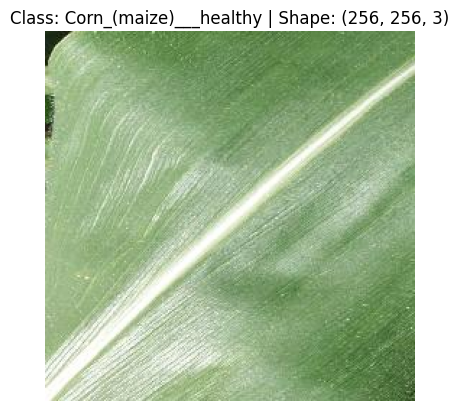

In [9]:
# Turn image into numpy array
img_as_array = np.asarray(img)

plt.imshow(img_as_array)
plt.title(f"Class: {image_class} | Shape: {img_as_array.shape}")
plt.axis(False)

### 3.4. Create DataLoaders

In this section, we recreate the training and testing datasets by applying the appropriate image transformations. We then create `DataLoader` objects for each dataset to enable efficient batch loading, shuffling, and data iteration during model training and evaluation.

In [10]:
from data_setup import create_transform
from data_setup import create_dataloader

# Create train and test transform
train_transform = create_transform(size=(224, 224), train=True)
test_transform = create_transform(size=(224, 224), train=False)

# Create train and test dataset
train_dataset = ImageDataset(targ_dir=train_path, transform=train_transform, subset_ratio=0.2, seed=42)
test_dataset = ImageDataset(targ_dir=test_path, transform=test_transform, subset_ratio=0.2, seed=42)

# Create train and test dataloader
train_dataloader = create_dataloader(dataset=train_dataset, batch_size=32, shuffle=True)
test_dataloader = create_dataloader(dataset=test_dataset, batch_size=32, shuffle=False)

### 3.5. Plot Random Images from the DataLoader

To verify that the preprocessing pipeline is applied correctly, we randomly sample a few images from the `DataLoader`, reverse the normalization for visualization, and display their corresponding class labels.

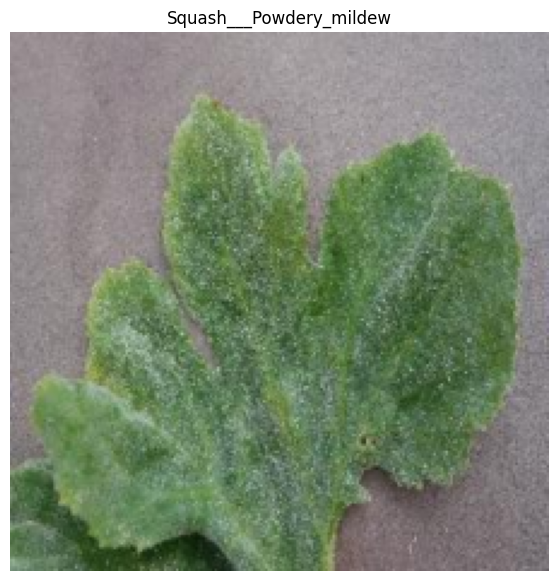

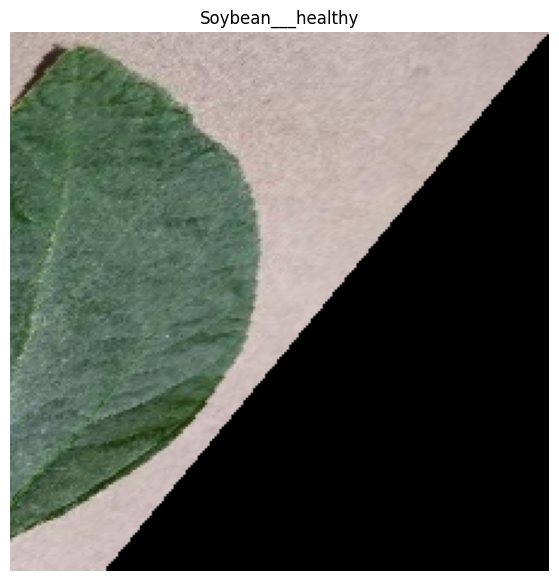

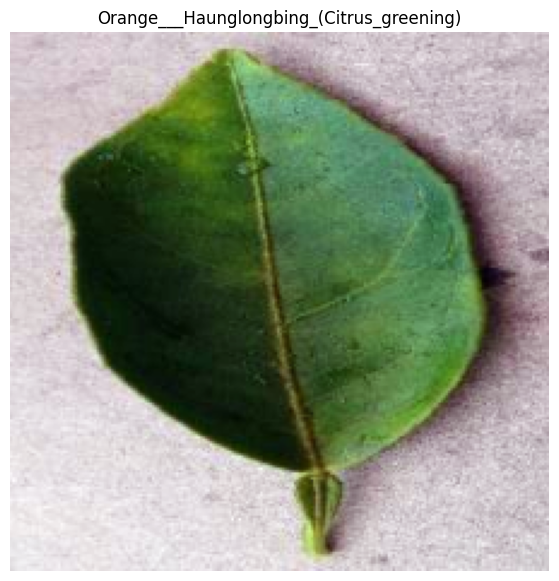

In [12]:
from utils import plot_transformed_images

plot_transformed_images(dataloader=train_dataloader, class_names=class_names, n=3, seed=42)